# Get Epigenetic Genes
---
### Imports and Installations

In [11]:
import csv
import time
import json
import requests
import pandas as pd
import matplotlib.pyplot as plt

### Download Genes from Reactome Tagged with "epigenetics"

In [ ]:
url = "https://reactome.org/ContentService"
search = "epigenetics"
species = "Homo sapiens"
output_file = "..data/epigenetic_genes/reactome_epigenetic_genes.csv"
delay = 0.05


def find_epigenetics_pathways():
    params = {
        "query": search,
        "species": species,
        "cluster": "true",
        "types": "Pathway",
        "rows": 100,
    }
    resp = requests.get(f"{url}/search/query", params=params, timeout=30)
    resp.raise_for_status()
    data = resp.json()
    pathways = []
    for group in data.get("results", []):
        pathways.extend(group.get("entries", []))
    return pathways


def get_contained_events(pathway_stid):
    resp = requests.get(f"{url}/data/pathway/{pathway_stid}/containedEvents", timeout=30)
    resp.raise_for_status()
    return resp.json()


def get_participants(event_stid):
    resp = requests.get(f"{url}/data/participants/{event_stid}", timeout=30)
    resp.raise_for_status()
    return resp.json()


def debug_inspect_participants():
    #print one raw participant record to confirm field names
    pathways = find_epigenetics_pathways()
    if not pathways:
        print("No pathways matched -- nothing to inspect.")
        return
    pw_stid = pathways[0].get("stId") or pathways[0].get("id")
    print(f"Inspecting pathway: {pw_stid} - {pathways[0].get('name')}")
    participants = get_participants(pw_stid)
    print(json.dumps(participants, indent=2)[:4000])


def main():
    print(f"Searching for pathways matching '{search}'...")
    pathways = find_epigenetics_pathways()
    print(f"Found {len(pathways)} matching pathways:")
    for p in pathways:
        print(f"  {p.get('stId')}: {p.get('name')}")

    gene_rows = {}

    for pathway in pathways:
        pw_stid = pathway.get("stId") or pathway.get("id")
        print(f"\nProcessing pathway {pw_stid} ({pathway.get('name')})...")

        def extract_id(item):
            if isinstance(item, dict):
                return item.get("stId") or item.get("id") or item.get("dbId")
            return item

        event_ids = {pw_stid}
        try:
            events = get_contained_events(pw_stid)
            for ev in events:
                ev_id = extract_id(ev)
                if ev_id:
                    event_ids.add(ev_id)
        except requests.HTTPError as e:
            print(f"  could not get contained events, using pathway id only: {e}")

        for ev_id in event_ids:
            try:
                participants = get_participants(ev_id)
            except requests.HTTPError:
                continue

            for p in participants:
                if not isinstance(p, dict):
                    print(f"  unexpected participant shape for {ev_id}: {p!r}")
                    continue
                participant_class = p.get("schemaClass")
                for ref in p.get("refEntities", []):
                    if not isinstance(ref, dict):
                        continue
                    if ref.get("schemaClass") != "ReferenceGeneProduct":
                        continue #skip small molecules/non-gene references

                    display_name = ref.get("displayName", "")
                    parts = display_name.split()
                    symbol = parts[-1] if len(parts) >= 2 else None
                    if not symbol:
                        continue

                    ref_class = ref.get("icon")

                    if symbol not in gene_rows:
                        gene_rows[symbol] = {
                            "hugo_symbol": symbol,
                            "uniprot_id": ref.get("identifier"),
                            "ref_entity_class": ref_class,
                            "participant_class": participant_class,
                            "source_pathway": pathway.get("name"),
                        }
            time.sleep(delay)

    with open(output_file, "w", newline="") as f:
        fieldnames = ["hugo_symbol", "uniprot_id", "ref_entity_class", "participant_class", "source_pathway"]
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(gene_rows.values())

    print(f"\nWrote {len(gene_rows)} unique genes to {output_file}")


if __name__ == "__main__":
    main()

### Combine Gene Lists

In [ ]:
my_headers = ['HugoSymbol', 'ERGClass']

output_file = "../data/epigenetic_genes/epigenetic_genes_with_duplicates.csv"

file1 = "..data/epigenetic_genes/epigeneticsGenes.csv"
file2 = "..data/epigenetic_genes/Gnad_ERG_Families.csv"
file3 = "../data/epigenetic_genes/Berdasco_Esteller_Genes.csv"
file4 = "../data/epigenetic_genes/reactome_epigenetic_genes.csv"

df1=pd.read_csv(file1, sep=';', header=0, names=my_headers, usecols=[0, 1], index_col=False)
df2=pd.read_csv(file2, sep=';', header=None, names=my_headers, usecols=[0, 2])
df3=pd.read_csv(file3, sep=';', header=None, names=my_headers, usecols=[0, 2])
df4=pd.read_csv(file4, header=None, names=['HugoSymbol'], usecols=[0])

combined_df = pd.concat([df1, df2, df3, df4], ignore_index=True)

combined_df = combined_df[combined_df["HugoSymbol"] != 'hugo_symbol']
combined_df = combined_df[combined_df["HugoSymbol"] != 'Gene Symbol']
combined_df = combined_df[combined_df["HugoSymbol"] != 'Gene']
combined_df = combined_df[combined_df["HugoSymbol"] != 'OTHER']


combined_df.to_csv(output_file, index=False)

### Remove Duplicates from Combined File and Clean Gene Classes

In [ ]:
input_file = "../data/epigenetic_genes/epigenetic_genes_with_duplicates.csv"
output_file = "../data/epigenetic_genes/epigenetic_genes_no_duplicates.csv"

df = pd.read_csv(input_file)

df_cleaned = df.drop_duplicates(subset=['HugoSymbol'])

df_cleaned.replace(to_replace="HDMT", value="HDM", inplace=True)
df_cleaned.replace(to_replace="HAT ", value="HAT", inplace=True)
df_cleaned.replace(to_replace="CHD", value="OTHER", inplace=True)
df_cleaned.replace(to_replace="STAGA-HAT", value="OTHER", inplace=True)
df_cleaned.replace(to_replace="SRCAP", value="OTHER", inplace=True)
df_cleaned.replace(to_replace="MDB", value="OTHER", inplace=True)

df_cleaned.to_csv(output_file, index=False)

print(df_cleaned['ERGClass'].unique())


<StringArray>
[       'BROMO/HMT',            'BROMO',        'BROMO/HAT',
              'HAT',             'HDAC',              'HDM',
              'HMT',           'SWISNF',            'OTHER',
         'HDAC/HAT',         'HMT/HDAC',     'HDAC/SWI/SNF',
 'HAT/SWI/SNF/HDAC',             'DNMT',                nan]
Length: 15, dtype: str


### Compare Gene Names with HGNC to Find Aliases


In [ ]:
gene_list = "../data/epigenetic_genes/epigenetic_genes_no_duplicates.csv"
hgnc_list = "../data/reference_data/hgnc_complete_set.txt"

hgnc_df = pd.read_csv(hgnc_list, sep="\t", low_memory=False)
gene_df = pd.read_csv(gene_list)

df_alias = gene_df.loc[~gene_df['HugoSymbol'].isin(hgnc_df['symbol'])]

print("Found", len(df_alias), "alias symbols in list.")
df_alias


Found 38 alias symbols in list.


,HugoSymbol,ERGClass
25,MLL,BROMO/HMT
71,C14orf169,HDM
75,JHDM1D,HDM
78,JMJD5,HDM
99,MINA,HDM
109,MLL2,HMT
110,MLL3,HMT
111,MLL4,HMT
112,MLL5,HMT
144,SETD8,HMT


### Map Approved Names to Aliases

In [187]:
alias_data = {
    "alias": ['MLL', 'C14orf169', 'JHDM1D', 'JMJD5', 'MINA', 'MLL2', 'MLL3', 'MLL4', 'MLL5', 'SETD8', 'SUV420H1', 'SUV420H2', 'WHSC1', 'WHSC1L1', 'CD3EAP', 'H2AFJ', 'H2AFV', 'H2AFX', 'H2BFS', 'HIST1H2AC', 'HIST1H2BB', 'HIST1H2BD', 'HIST1H2BH', 'HIST1H2BO', 'HIST2H2AA3', 'HIST2H2AC', 'HIST2H2BE', 'HIST2H3A', 'HIST3H2BB', 'TWISTNB', 'ZNRD1', 'DNMT3', 'DNMT3b', 'MYST4', 'NSDI', 'JMJD3', 'JARID1C'],
    "approved": ['KMT2A', 'RIOX1', 'KDM7A', 'KDM8', 'RIOX2', 'KMT2B', 'KMT2C', 'KMT2D', 'KMT2E', 'KMT5A', 'KMT5B', 'KMT5C', 'NSD2', 'NSD3', 'POLR1G', 'H2AJ', 'H2AZ2', 'H2AX', 'H2BC12L', 'H2AC6', 'H2BC3', 'H2BC5', 'H2BC9', 'H2BC17', 'H2AC18', 'H2AC20', 'H2BC21', 'H3C15', 'H2BC26', 'POLR1F', 'POLR1H', 'DNMT3', 'DNMT3B', 'KAT6B', 'NSD1', 'KDM6B', 'KDM5C'],
    "class": ['BROMO/HMT', 'HDM', 'HDM', 'HDM', 'HDM', 'HMT', 'HMT', 'HMT', 'HMT', 'HMT', 'HMT', 'HMT', 'HMT', 'HMT', 'OTHER', 'OTHER', 'OTHER', 'OTHER', 'OTHER', 'HDAC/HAT', 'HDAC/HAT', 'HDAC/HAT', 'HDAC/HAT', 'HDAC/HAT', 'HDAC/HAT', 'HDAC/HAT', 'HDAC/HAT', 'HDAC/HAT', 'HDAC/HAT', 'OTHER', 'OTHER', 'DNMT', 'DNMT', 'HAT', 'HDM', 'HDM', 'HDM']
}

alias_df = pd.DataFrame(alias_data)


alias_df

,alias,approved,class
0,MLL,KMT2A,BROMO/HMT
1,C14orf169,RIOX1,HDM
2,JHDM1D,KDM7A,HDM
3,JMJD5,KDM8,HDM
4,MINA,RIOX2,HDM
5,MLL2,KMT2B,HMT
6,MLL3,KMT2C,HMT
7,MLL4,KMT2D,HMT
8,MLL5,KMT2E,HMT
9,SETD8,KMT5A,HMT


### Check epigenetic_genes_no_duplicates.csv for Approved Names of Present Aliases

In [ ]:
approved_df = gene_df.loc[gene_df['HugoSymbol'].isin(alias_df['approved'])] 
#approved_df contains all approved symbols that are in the original gene list that also have their alias in the gene list

print("Found", len(approved_df), "approved symbols where the alias is also present.")

approved_df 


Found 27 approved symbols where the alias is also present.


,HugoSymbol,ERGClass
48,KAT6B,HAT
95,KDM5C,HDM
98,KDM6B,HDM
113,NSD1,HMT
188,DNMT3B,HMT
281,DNMT3,DNMT
293,H2BC5,NaN
294,H2BC9,NaN
295,H2BC21,NaN
296,H2BC17,NaN


### Remove Entries that Already Contain Approved Names that also have Aliases, then Replace Alias Names with Approved Names

In [ ]:
output_file = "../data/epigenetic_genes/clean_epigenetic_genes.csv"

cleaned_df = gene_df[~gene_df['HugoSymbol'].isin(approved_df['HugoSymbol'])].reset_index(drop=True)

removed = len(df_alias)-1

print("Removed", removed,  "approved symbols where the alias is also present.")

for i, row in cleaned_df.iterrows():
    match = alias_df.loc[alias_df['alias'] == row['HugoSymbol'], 'approved']
    if not match.empty:
        old_symbol = row['HugoSymbol']
        new_symbol = match.iloc[0]
        cleaned_df.at[i, 'HugoSymbol'] = new_symbol
        print(f"Renamed {old_symbol} -> {new_symbol}")


cleaned_df = cleaned_df[cleaned_df['HugoSymbol'] != "OTHER"]

cleaned_df.to_csv(output_file, index=False)


Removed 37 approved symbols where the alias is also present.
Renamed MLL -> KMT2A
Renamed C14orf169 -> RIOX1
Renamed JHDM1D -> KDM7A
Renamed JMJD5 -> KDM8
Renamed MINA -> RIOX2
Renamed MLL2 -> KMT2B
Renamed MLL3 -> KMT2C
Renamed MLL4 -> KMT2D
Renamed MLL5 -> KMT2E
Renamed SETD8 -> KMT5A
Renamed SUV420H1 -> KMT5B
Renamed SUV420H2 -> KMT5C
Renamed WHSC1 -> NSD2
Renamed WHSC1L1 -> NSD3
Renamed CD3EAP -> POLR1G
Renamed H2AFJ -> H2AJ
Renamed H2AFV -> H2AZ2
Renamed H2AFX -> H2AX
Renamed H2BFS -> H2BC12L
Renamed HIST1H2AC -> H2AC6
Renamed HIST1H2BB -> H2BC3
Renamed HIST1H2BD -> H2BC5
Renamed HIST1H2BH -> H2BC9
Renamed HIST1H2BO -> H2BC17
Renamed HIST2H2AA3 -> H2AC18
Renamed HIST2H2AC -> H2AC20
Renamed HIST2H2BE -> H2BC21
Renamed HIST2H3A -> H3C15
Renamed HIST3H2BB -> H2BC26
Renamed TWISTNB -> POLR1F
Renamed ZNRD1 -> POLR1H
Renamed DNMT3b -> DNMT3B
Renamed MYST4 -> KAT6B
Renamed NSDI -> NSD1
Renamed JMJD3 -> KDM6B
Renamed JARID1C -> KDM5C


### Find All Genes Without Assigned Class

In [ ]:
input_file = "../data/epigenetic_genes/clean_epigenetic_genes.csv"
hgnc_file = "../data/reference_data/hgnc_complete_set.txt"

hgnc_df = pd.read_csv(hgnc_file, sep="\t", low_memory=False)
df = pd.read_csv(input_file)

no_class_df = df[df['ERGClass'].isnull()]

gene_symbols = list(no_class_df['HugoSymbol'].unique())

gene_groups = hgnc_df[hgnc_df['symbol'].isin(gene_symbols)][['symbol', 'gene_group']]

print("Genes:", len(no_class_df))
print(gene_groups['gene_group'].value_counts())

Genes: 263
gene_group
Zinc fingers C2H2-type|KRAB domain containing                                                                                 29
Proteasome                                                                                                                    21
Mediator complex                                                                                                              13
Oligosaccharyltransferase complex subunits                                                                                     6
AAA ATPases|Proteasome                                                                                                         6
TCF/LEF transcription factor family|Wnt enhanceosome complex                                                                   4
TEA domain transcription factors                                                                                               4
RISC loading complex subunits|Argonaute RISC component family              

### Get List of Genes for Each Class with 10 or More Members

In [220]:
ZNF = gene_groups[gene_groups['gene_group'].str.contains('Zinc fingers C2H2-type')]
print("Zinc fingers C2H2-type", "(", len(ZNF), ")")
print("----------")
print(ZNF)

PRT = gene_groups[gene_groups['gene_group'].str.contains('Proteasome')]
print("Proteasome", "(", len(PRT), ")")
print("----------")
print(PRT)

MED = gene_groups[gene_groups['gene_group'].str.contains('Mediator complex')]
print("Mediator complex", "(", len(MED), ")")
print("----------")
print(MED)

Zinc fingers C2H2-type ( 31 )
----------
        symbol  \
19618    PHF20   
39473    ZNF28   
39475    ZNF30   
39480   ZNF33A   
39527    ZNF93   
39550   ZNF136   
39554   ZNF141   
39598   ZNF224   
39623   ZNF257   
39626   ZNF264   
39631   ZNF273   
39664   ZNF317   
39668   ZNF320   
39672   ZNF324   
39676   ZNF331   
39691  ZNF354A   
39700   ZNF382   
39726   ZNF418   
39730   ZNF425   
39755   ZNF454   
39811   ZNF519   
39828   ZNF534   
39837   ZNF547   
39910   ZNF610   
39941   ZNF649   
39959   ZNF669   
39971   ZNF680   
40002   ZNF708   
40052   ZNF765   
40065   ZNF778   
40095   ZNF816   

                                                                                                     gene_group  
19618  Zinc fingers C2H2-type|PHD finger proteins|Tudor domain containing|NSL histone acetyltransferase complex  
39473                                                             Zinc fingers C2H2-type|KRAB domain containing  
39475                                   

### Assign Classes to Genes

In [ ]:
input_file = "../data/epigenetic_genes/clean_epigenetic_genes.csv"
output_file = "../data/epigenetic_genes/all_epigenetic_genes.csv"

df = pd.read_csv(input_file)

for i, row in df.iterrows():
    if row['HugoSymbol'].startswith('ZNF'):
        df.at[i, 'ERGClass'] = 'ZNF'
    elif row['HugoSymbol'].startswith('PSM'):
        df.at[i, 'ERGClass'] = 'PRT'
    elif row['HugoSymbol'].startswith('MED'):
        df.at[i, 'ERGClass'] = 'MED'
    elif pd.isna(df.loc[i, 'ERGClass']):
        df.at[i, 'ERGClass'] = 'OTHER'

df.to_csv(output_file, index=False)

### Get Class Counts

ERGClass
OTHER               242
HMT                  60
BROMO                35
HDAC                 33
HDM                  33
ZNF                  30
PRT                  30
HDAC/HAT             22
SWISNF               20
MED                  16
HAT                  14
BROMO/HAT             6
HMT/HDAC              2
DNMT                  2
BROMO/HMT             2
HDAC/SWI/SNF          1
HAT/SWI/SNF/HDAC      1
Name: count, dtype: int64


<function matplotlib.pyplot.show(close=None, block=None)>

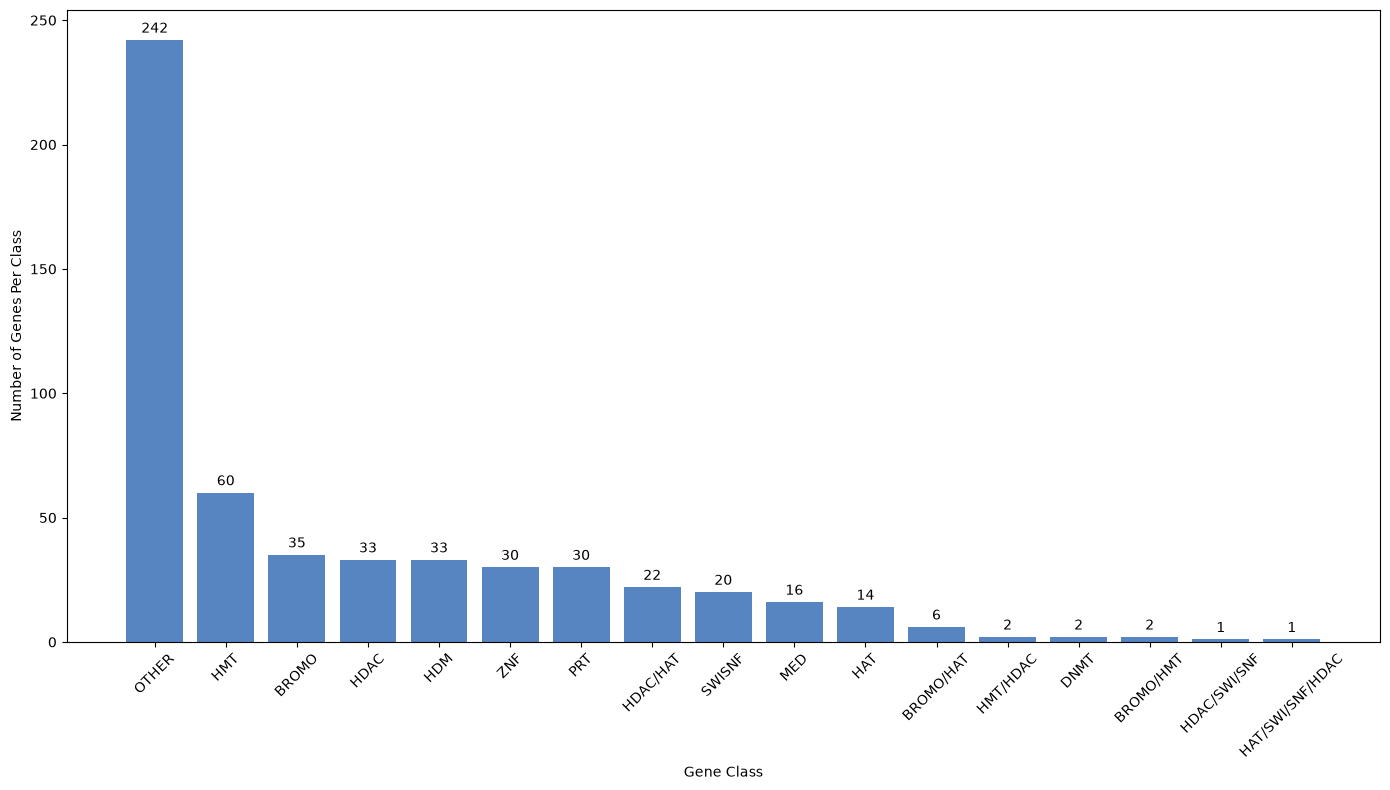

In [27]:
input_file = "../data/epigenetic_genes/all_epigenetic_genes.csv"
df = pd.read_csv(input_file)

counts = df['ERGClass'].value_counts()

print(counts)

plt.figure(figsize=(14, 8))
bars = plt.bar(counts.index, counts.values, color="#5785C1")
plt.bar_label(bars, padding=3)
plt.xticks(rotation=45)
plt.xlabel('Gene Class')
plt.ylabel('Number of Genes Per Class')
plt.tight_layout()
plt.savefig('../data/epigenetic_genes/genes_per_class.png')
plt.show